# Assignment 3 — Exercise 2: Dynamic SABR

We calibrate the dynamic SABR implied-volatility approximation to the 12 STOXX50 quotes in the assignment.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import quad
from scipy.optimize import least_squares
from scipy.stats import norm

SEED = 42
plt.style.use("seaborn-v0_8")

## 1. Market data

Exercise 2 delivers the 12 quotes in its own table. The strikes are fractions of the current price. We normalize the forward to $F_0=1$. Equivalently, we assume zero carry because no rates or dividend yields are given for Exercise 2. Volatilities below are decimals (not percentages).

In [2]:
forward = 1.0
strikes = np.array([0.88, 1.00, 1.12])
maturities = np.array([0.25, 0.50, 1.00, 2.00])

market_vols = pd.DataFrame(
    [
        [0.3221, 0.3207, 0.3011, 0.2816],
        [0.2979, 0.2963, 0.2822, 0.2654],
        [0.2752, 0.2742, 0.2634, 0.2495],
    ],
    index=strikes,
    columns=maturities,
)
market_vols.index.name = "K / F"
market_vols.columns.name = "T (years)"
display(market_vols)

T (years),0.25,0.50,1.00,2.00
K / F,,,,
0.88,0.3221,0.3207,0.3011,0.2816
1.00,0.2979,0.2963,0.2822,0.2654
1.12,0.2752,0.2742,0.2634,0.2495


## 2. Dynamic SABR implied volatility

We use equations (9)–(11) of *SABR_calibration.pdf* and the formulas in *Lecture 4-5.pdf*, slides 6–7. In the assignment/lecture notation, $\sigma_0$ is initial volatility and $\alpha_0$ is initial volatility of volatility. The paper calls these $\alpha$ and $\nu_0$, respectively.

For each maturity, the four helper terms $\nu_1^2, \nu_2^2, \eta_1, \eta_2^2$ come from the integrals in paper equation (10). Evaluating those smooth one-dimensional integrals numerically avoids cancellation in the closed forms when \(a\) or \(b\) is near zero. The double integral for $\eta_2^2$ is reduced to one dimension by changing the order of integration.

In [3]:
def sabr_terms(T: float, rho0: float, alpha0: float, a: float, b: float):
    decay = a + b

    nu1_sq = 3 / T**3 * quad(
        lambda t: (T - t)**2 * (alpha0 * np.exp(-b * t))**2, 0, T
    )[0]
    nu2_sq = 6 / T**3 * quad(
        lambda t: (T - t) * t * (alpha0 * np.exp(-b * t))**2, 0, T
    )[0]
    eta1 = 2 / T**2 * quad(
        lambda t: (T - t) * alpha0 * rho0 * np.exp(-decay * t), 0, T
    )[0]

    # Integral from 0 to s of alpha(u)*rho(u) du.
    def integrated_alpha_rho(s):
        return alpha0 * rho0 * (-np.expm1(-decay * s)) / decay

    eta2_sq = 12 / T**4 * quad(
        lambda s: (T - s) * integrated_alpha_rho(s)**2, 0, T
    )[0]
    return nu1_sq, nu2_sq, eta1, eta2_sq

In [4]:
def sabr_implied_vol(K: np.ndarray, T: float, params: np.ndarray, F: float = 1.0) -> np.ndarray:
    sigma0, beta, rho0, alpha0, a, b = params
    omega = F**(1 - beta) / sigma0
    nu1_sq, nu2_sq, eta1, eta2_sq = sabr_terms(T, rho0, alpha0, a, b)

    A1 = (beta - 1 + eta1 * omega) / 2
    A2 = (
        (1 - beta)**2 / 12
        + (1 - beta - eta1 * omega) / 4
        + (4 * nu1_sq + 3 * (eta2_sq - 3 * eta1**2)) * omega**2 / 24
    )
    B = (
        (1 - beta)**2 / 24
        + beta * eta1 * omega / 4
        + (2 * nu2_sq - 3 * eta2_sq) * omega**2 / 24
    ) / omega**2

    log_moneyness = np.log(np.asarray(K) / F)
    return (1 + A1 * log_moneyness + A2 * log_moneyness**2 + B * T) / omega

## 3. Calibrate to all 12 quotes

Fit $(\sigma_0, \beta, \rho_0, \alpha_0, a, b)$ jointly by minimizing the differences between model and market implied volatilities. We use the usual SABR range $0\leq\beta\leq1$ and the correlation range $-1\leq\rho_0\leq1$. The model requires $\sigma_0, \alpha_0, a, b>0$, so the optimizer uses a small positive floor $10^{-6}$ for these parameters. There is no upper bound on them. We use one reproducible random starting point; its sampling ranges are not calibration bounds.

In [5]:
def calibration_errors(params: np.ndarray) -> np.ndarray:
    fitted = np.column_stack([
        sabr_implied_vol(strikes, T, params, forward) for T in maturities
    ])
    return (fitted - market_vols.to_numpy()).ravel()

parameter_names = ["sigma0", "beta", "rho0", "alpha0", "a", "b"]
positive_floor = 1e-6
lower_bounds = [positive_floor, 0.0, -1.0, positive_floor, positive_floor, positive_floor]
upper_bounds = [np.inf, 1.0, 1.0, np.inf, np.inf, np.inf]

rng = np.random.default_rng(SEED)
initial_guess = [
    rng.uniform(0.20, 0.40), rng.uniform(0, 1), rng.uniform(-0.9, 0.9),
    rng.uniform(0.10, 0.80), rng.uniform(0.01, 1), rng.uniform(0.01, 1),
]

fit = least_squares(calibration_errors, initial_guess,
                    bounds=(lower_bounds, upper_bounds))
if not fit.success:
    raise RuntimeError(f"Calibration did not converge: {fit.message}")

calibrated_params = fit.x
display(pd.DataFrame({"calibrated value": calibrated_params}, index=parameter_names))

,calibrated value
sigma0,0.294404
beta,1.000000
rho0,-1.000000
alpha0,0.405663
a,0.000001
b,0.091302


In [6]:
fitted_vols = pd.DataFrame(
    np.column_stack([
        sabr_implied_vol(strikes, T, calibrated_params, forward) for T in maturities
    ]),
    index=strikes,
    columns=maturities,
)
fitted_vols.index.name = "K / F"
fitted_vols.columns.name = "T (years)"

errors_in_vol_points = 100 * (fitted_vols - market_vols)
rmse = np.sqrt(np.mean(calibration_errors(calibrated_params)**2))

print(f"RMSE: {100 * rmse:.4f} volatility percentage points")
print(f"Largest absolute error: {errors_in_vol_points.abs().to_numpy().max():.4f} volatility percentage points")
print("Model implied volatilities:")
display(fitted_vols.round(4))
print("Model minus market (volatility percentage points):")
display(errors_in_vol_points.round(3))

RMSE: 0.7529 volatility percentage points
Largest absolute error: 1.7483 volatility percentage points
Model implied volatilities:


T (years),0.25,0.50,1.00,2.00
K / F,,,,
0.88,0.3184,0.3155,0.3099,0.2991
1.00,0.2917,0.2891,0.2838,0.2737
1.12,0.2696,0.2671,0.2622,0.2528


Model minus market (volatility percentage points):


T (years),0.25,0.50,1.00,2.00
K / F,,,,
0.88,-0.375,-0.520,0.881,1.748
1.00,-0.618,-0.724,0.163,0.832
1.12,-0.559,-0.707,-0.115,0.331


## 4. Volatility smiles

Each panel shows the fitted smile at one quoted maturity, with the three observed market volatilities marked as points. The curves are evaluated on a denser strike grid.

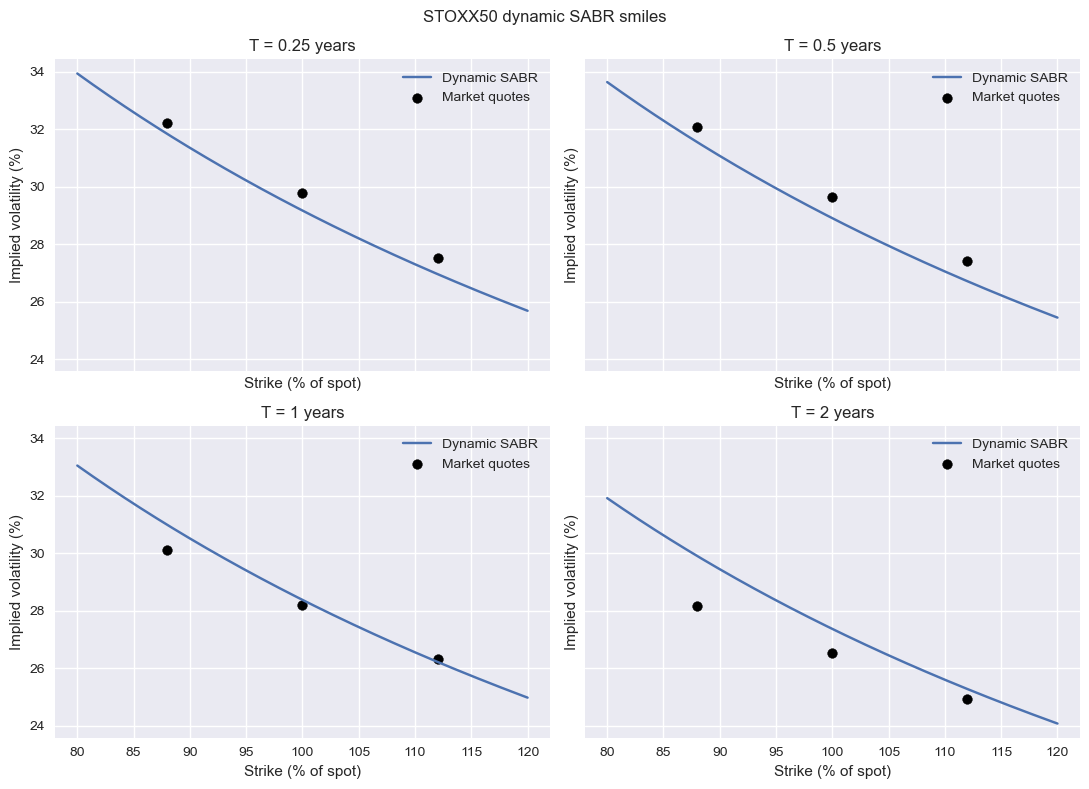

In [7]:
plot_strikes = np.linspace(0.80, 1.20, 200)
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)

for ax, T in zip(axes.flat, maturities):
    model_curve = sabr_implied_vol(plot_strikes, T, calibrated_params, forward)
    ax.plot(100 * plot_strikes, 100 * model_curve, label="Dynamic SABR")
    ax.scatter(100 * strikes, 100 * market_vols[T], color="black", label="Market quotes")
    ax.set_title(f"T = {T:g} years")
    ax.set_xlabel("Strike (% of spot)")
    ax.set_ylabel("Implied volatility (%)")
    ax.legend()

fig.suptitle("STOXX50 dynamic SABR smiles")
fig.tight_layout()

fig.savefig("figures/dynamic_sabr_smiles.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Implied volatility surface

The surface evaluates the calibrated SABR formula on a dense strike-maturity grid. The red dots are the 12 market quotes.

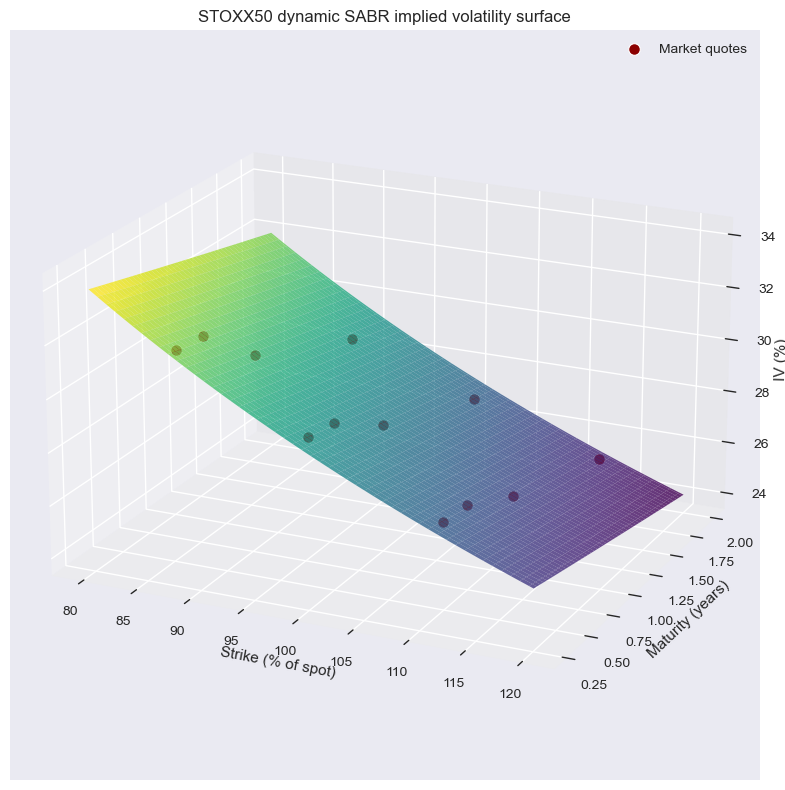

In [8]:
surface_strikes = np.linspace(0.80, 1.20, 100)
surface_maturities = np.linspace(0.25, 2.00, 100)
strike_grid, maturity_grid = np.meshgrid(surface_strikes, surface_maturities)
surface_vols = np.array([
    sabr_implied_vol(surface_strikes, T, calibrated_params, forward)
    for T in surface_maturities
])
market_strike_grid, market_maturity_grid = np.meshgrid(strikes, maturities)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(100 * strike_grid, maturity_grid, 100 * surface_vols,
                cmap="viridis", linewidth=0, antialiased=True, alpha=0.80)
ax.scatter(100 * market_strike_grid, market_maturity_grid,
           100 * market_vols.to_numpy().T, color="darkred", s=70,
           edgecolors="white", linewidths=0.8, depthshade=False,
           label="Market quotes")
ax.set_xlabel("Strike (% of spot)")
ax.set_ylabel("Maturity (years)")
ax.set_zlabel("IV (%)", labelpad=2)
ax.set_title("STOXX50 dynamic SABR implied volatility surface")
ax.view_init(elev=20, azim=-65)
ax.set_box_aspect((1.2, 1, 0.7))
ax.legend()
fig.tight_layout()
fig.savefig("figures/dynamic_sabr_surface.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Example price at another strike and maturity

The SABR formula gives an implied volatility at any chosen $K,T$. We then put that volatility into Black-Scholes. With the normalized forward $F_0=1$ and zero interest rate, the example call price is per unit of forward/notional.

In [9]:
def black_scholes_call(F: float, K: float, T: float, vol: float) -> float:
    d1 = (np.log(F / K) + 0.5 * vol**2 * T) / (vol * np.sqrt(T))
    d2 = d1 - vol * np.sqrt(T)
    return F * norm.cdf(d1) - K * norm.cdf(d2)

example_strike = 1.05
example_maturity = 0.75
example_iv = sabr_implied_vol(example_strike, example_maturity, calibrated_params, forward)
example_call = black_scholes_call(forward, example_strike, example_maturity, example_iv)

print(f"K/F = {example_strike:.2f}, T = {example_maturity:.2f}")
print(f"Model implied volatility: {example_iv:.2%}")
print(f"Call price per unit of forward: {example_call:.6f}")

K/F = 1.05, T = 0.75
Model implied volatility: 27.69%
Call price per unit of forward: 0.074828
